# アルゴリズム論Ⅱ 

## 第6回：ルンゲ＝クッタ法（常微分方程式の数値解法）

前回の「第5回：最急降下法」では、関数の傾き（勾配）を手がかりに、目的関数を最小化するパラメータ最適化アルゴリズムを学びました。最急降下法は機械学習やデータ分析で大活躍しますが、現実世界の現象——お湯が冷める速さ、車の加速と減速、振り子の揺れ、回路を流れる電流、感染症の流行——は、静止した答えを探すだけでなく、**「時間が進むにつれて状態がどう変化していくか」という未来の道のり（ダイナミクス）** を予測する必要があります。

このような「時間とともに刻々と変化する現象」を数学的に表したものが **「常微分方程式（Ordinary Differential Equations: ODE）」** です。

---

### そもそも「微分方程式」とは何か？

「微分方程式」と聞くと難しそうに感じるかもしれませんが、その発想はとてもシンプルで身近です。

#### 1. 普通の方程式との違い
- **普通の方程式**（例: $x^2 - 4 = 0$）  
  → 答えは「$x = 2$」のような **特定の数値（止まっている1点）** です。
- **微分方程式**（例: $\frac{dy}{dt} = -y$）  
  → 答えは **「時間の経過とともに変化していくカーブ（未来の航跡：関数 $y(t)$）」** そのものです。

#### 2. 身近なたとえ話
- **お湯が冷める現象（ニュートンの冷却則）**:  
  沸騰した熱湯は最初はすごい勢いで冷めますが、ぬるま湯になるとゆっくり冷めます。つまり、「冷めるスピード（変化率 $\frac{dy}{dt}$）」は「現在の温度 $y$ と室温の差」によって決まります。
- **車の走行**:  
  現在位置を $y$ とすると、車のスピードメーターが指している値が変化率（速度 $\frac{dy}{dt}$）です。
- **スマホの充電**:  
  バッテリー残量 $y$ が少ないときは急速に充電され、100%に近づくにつれてゆっくり充電されます。

> **💡 微分方程式の正体**  
> 微分方程式とは、**「今の状態 $y$ を入力すると、次の瞬間に『どっちへ、どれくらいの勢いで変化するか（スピード・傾き $f(t, y)$）』を教えてくれるナビゲーションのルール」** です！  
> そして、コンピュータで微分方程式を解く（シミュレーションする）とは、**「ナビが指示するスピードの矢印に従って、未来の道のりを1歩ずつ歩いていくこと」** に他なりません。

---

### 今回学ぶアルゴリズム：オイラー法とルンゲ＝クッタ法
- **オイラー法（Euler's method）**:  
  「今いる場所のスピードだけを見て、次の交差点までハンドルをまっすぐ固定して進む」最も単純な方法。しかし、カーブした道路をまっすぐ走るため、カーブの外側へどんどん脱線してしまう弱点があります。
- **ルンゲ＝クッタ法（Runge-Kutta method / RK4）**:  
  「いきなり進むのではなく、途中の道のり（中間地点）を4回下見（予測）して、スピードを賢くブレンドして進む」画期的な方法。難しい微分の手計算をしなくても、関数の値を4回計算するだけで、道路のカーブにピタリと吸い付くように正確に未来を予測できます。

本講義では、微分方程式の基礎から始めて、オイラー法がなぜ脱線するのか、そしてルンゲ＝クッタ法がなぜ驚くほど正確なのかを、直感的な図とプログラムで解き明かしていきます。

---
## 1. オイラー法とルンゲ＝クッタ法の原理

### 微分方程式の基本形（初期値問題）
時間を $t$、追跡したい状態（温度や位置など）を $y(t)$ とします。  
1階常微分方程式の初期値問題は、次のように書かれます：

$$
\frac{dy}{dt} = f(t, y), \quad y(t_0) = y_0
$$

- $y(t_0) = y_0$：スタート地点（初期状態）
- $f(t, y)$：現在時刻 $t$ と現在の状態 $y$ における **「変化のスピード（傾き）」**

コンピュータでは、時間を微小な歩幅（刻み幅）$h$（例: $0.1$ 秒ごと）で区切り、
$t_0, t_1, t_2, \dots$ における状態 $y_0, y_1, y_2, \dots$ を順番に計算していきます。

---

### オイラー法（Euler's Method）の仕組みと弱点
最も素朴な方法は、「現在地 $(t_n, y_n)$ での傾き $f(t_n, y_n)$ の方向に、歩幅 $h$ だけ直線で進む」ことです：

$$
y_{n+1} = y_n + h \cdot f(t_n, y_n)
$$

- **直感的なイメージ**:  
  曲がりくねった坂道を下るときに、「足元の地面の傾き」だけを見て、目を閉じたまま大股で 1 歩踏み出すようなものです。
- **弱点**:  
  道路が急に曲がっていても直進してしまうため、真のカーブからどんどんズレていきます（**1次精度**：大域誤差 $O(h)$）。  
  歩幅 $h$ を半分にしても、誤差は半分にしかなりません。

---

### ルンゲ＝クッタ法（RK4）の知恵：4回の下見で賢く進む
オイラー法のように「今の場所の傾き」だけで進むのではなく、**「ちょっと先を偵察（下見）してから進む」** のがルンゲ＝クッタ法です。  
中でも世界標準として使われている **4次ルンゲ＝クッタ法（RK4）** は、1歩進む間に次の **4つの傾き** をサンプリングします：

1. **$k_1$（現在地の傾き）**:  
   今の場所でのスピード（オイラー法と同じ傾き）。
2. **$k_2$（中点での下見 ①）**:  
   $k_1$ の傾きを頼りに「半歩先（中点 $t_n + h/2$）」まで軽く進んでみた地点のスピード。
3. **$k_3$（中点での下見 ②）**:  
   より正確な $k_2$ の傾きを頼りに、もう一度「半歩先」を見直した地点のスピード。
4. **$k_4$（終点での下見）**:  
   中点の傾き $k_3$ を頼りに、一気に「1歩先（終点 $t_n + h$）」まで進んでみた地点のスピード。

そして、得られた4つの傾きを **「$1 : 2 : 2 : 1$」** の重みでブレンド（加重平均）して、次の位置を決めます：

$$
y_{n+1} = y_n + \frac{h}{6} (k_1 + 2 k_2 + 2 k_3 + k_4)
$$

> **✨ なぜ 1 : 2 : 2 : 1 なのか？**  
> 真ん中付近（中点）の傾き $k_2, k_3$ は区間全体を代表する最も重要な情報なので、端っこ（$k_1, k_4$）の2倍重視します。  
> これにより、手計算で難しい微分をしなくても、**4次精度**（大域誤差 $O(h^4)$）という驚異的な正確さを達成できます。  
> 
> **歩幅 $h$ を半分（$1/2$）にするだけで、誤差はなんと $(1/2)^4 = 1/16$（約 $6.25\%$）に激減します！**  
> 歩幅を $1/10$ にすれば、誤差は一気に **1万分の1** にまで縮小します。

---
## 2. 基本実装と動作検証（オイラー法 vs 4次ルンゲ＝クッタ法）

実際に Python でオイラー法と RK4 を実装し、手計算で正解（真解）が分かっている次の微分方程式で精度の違いを検証してみましょう。

### 検証する微分方程式
$$
\frac{dy}{dt} = y - t^2 + 1, \quad y(0) = 0.5 \quad (0 \le t \le 2)
$$

この方程式の数学的な厳密解（真のカーブ）は以下になります：
$$
y(t) = (t + 1)^2 - 0.5 e^t
$$

あえて $h = 0.2$ という「かなり大股（粗い歩幅）」で計算し、オイラー法と RK4 がどのように追従するかを比較します。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 微分方程式の右辺 f(t, y) と真の解 y_true(t)
def f(t, y):
    return y - t**2 + 1.0

def y_true(t):
    return (t + 1.0)**2 - 0.5 * np.exp(t)

# 2. オイラー法（Euler法）の実装
def euler_step(f, t, y, h):
    return y + h * f(t, y)

# 3. 4次ルンゲ＝クッタ法（RK4）の実装
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# 4. シミュレーション実行
t0, y0 = 0.0, 0.5
t_end = 2.0
h = 0.2
n_steps = int(round((t_end - t0) / h))

t_hist = [t0]
y_euler_hist = [y0]
y_rk4_hist = [y0]

t_curr = t0
y_e = y0
y_r = y0

for _ in range(n_steps):
    y_e = euler_step(f, t_curr, y_e, h)
    y_r = rk4_step(f, t_curr, y_r, h)
    t_curr += h
    
    t_hist.append(t_curr)
    y_euler_hist.append(y_e)
    y_rk4_hist.append(y_r)

# 5. ステップ推移と誤差比較テーブルの出力
print(f"{'Step':>5} | {'時刻 t':>6} | {'Euler解':>10} | {'RK4解':>10} | {'真解':>10} | {'Euler誤差':>12} | {'RK4誤差':>12}")
print("-" * 75)
for n in range(len(t_hist)):
    tn = t_hist[n]
    ye = y_euler_hist[n]
    yr = y_rk4_hist[n]
    yt = y_true(tn)
    print(f"{n:5d} | {tn:6.2f} | {ye:10.5f} | {yr:10.5f} | {yt:10.5f} | {abs(ye - yt):12.4e} | {abs(yr - yt):12.4e}")

print("-" * 75)
print(f"最終地点での誤差比較: RK4はオイラー法より 約 {abs(y_euler_hist[-1] - y_true(t_end)) / abs(y_rk4_hist[-1] - y_true(t_end)):.0f} 倍 正確！")

# 6. 可視化（解曲線の比較）
fig, ax = plt.subplots(figsize=(10, 6))

t_fine = np.linspace(t0, t_end, 200)
ax.plot(t_fine, y_true(t_fine), 'b-', lw=3.0, label='真の厳密解 $y(t)$')
ax.plot(t_hist, y_euler_hist, 'ro--', lw=2.2, markersize=8, label=f'オイラー法 ($h={h}$)')
ax.plot(t_hist, y_rk4_hist, 'gs-', lw=2.2, markersize=8, label=f'4次ルンゲ＝クッタ法 RK4 ($h={h}$)')
ax.set_title('微分方程式の解曲線比較：オイラー法 vs 4次ルンゲ＝クッタ法', fontsize=15, pad=12)
ax.set_xlabel('時刻 $t$', fontsize=13)
ax.set_ylabel('状態 $y(t)$', fontsize=13)
ax.tick_params(labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=12, loc='upper left')

plt.tight_layout()
plt.show()

---
### ルンゲ＝クッタ法のアルゴリズムをアニメーションで学ぶ

オイラー法のズレや、ルンゲ＝クッタ法（RK4）が途中の傾きを4回下見して高精度にカーブを捉える様子を、直感的に確認できるHTMLアニメーション教材を用意しています：

- [https://kita-toshihiro.github.io/algoII/runge1.html](https://kita-toshihiro.github.io/algoII/runge1.html)

ブラウザ上でステップ実行ボタンを押しながら、オイラー法がコースから外れていく様子や、RK4の4つの下見ベクトル（$k_1, k_2, k_3, k_4$）がどのように組み合わさるかを体感してみましょう。

---
## 3. 実際の計算での落とし穴 1：振り子・バネにおける（見かけ上の）エネルギー増加

ゲームの物理エンジン（キャラクターのジャンプやバネ）、振り子の時計、電子回路（LC共振回路）などで最も基本となるのが **「単振動（調和振動子）」** です。  
しかし、この美しい振動現象に対してオイラー法を使うと、**物理法則に反して勝手にエネルギーが湧き出し、解が外側へ吹き飛ぶという数値計算上の現象が起きます。**

### 振り子の数理モデル
位置 $x(t)$ と速度 $v(t)$ の関係は、次の連立方程式で表されます：

$$
\frac{dx}{dt} = v, \quad \frac{dv}{dt} = -\omega^2 x
$$

物理学の基本法則により、摩擦がない振り子の全エネルギー $E(t) = \frac{1}{2} v^2 + \frac{1}{2} \omega^2 x^2$ は **永遠に一定** でなければならず、位置 $x$ と速度 $v$ のグラフ（位相平面）は **きれいな円（閉軌道）** をぐるぐる周り続けるはずです。

### なぜオイラー法は発散するのか？
オイラー法で1歩進めると、次のエネルギー $E_{n+1}$ は必ず元のエネルギー $E_n$ の $(1 + \omega^2 h^2)$ 倍に増えてしまいます。  
歩幅 $h$ がどんなに小さくても、$1 + \omega^2 h^2 > 1.0$ ですから、**1歩進むたびにエネルギーが自己増殖し、外側へ螺旋を描いて解が広がっていきます**。

一方、4次ルンゲ＝クッタ法（RK4）は4回の下見のおかげでエネルギーの増大が極小に抑えられ、綺麗な円軌道を長期間にわたって正確にキープできます。

初期エネルギー E0: 2.0000
最終時刻でのオイラー法のエネルギー: 107.0482 （初期値の 53.5 倍に増大）
最終時刻での RK4 のエネルギー    : 1.999989 （初期値比 0.999994、極めて正確に保存）


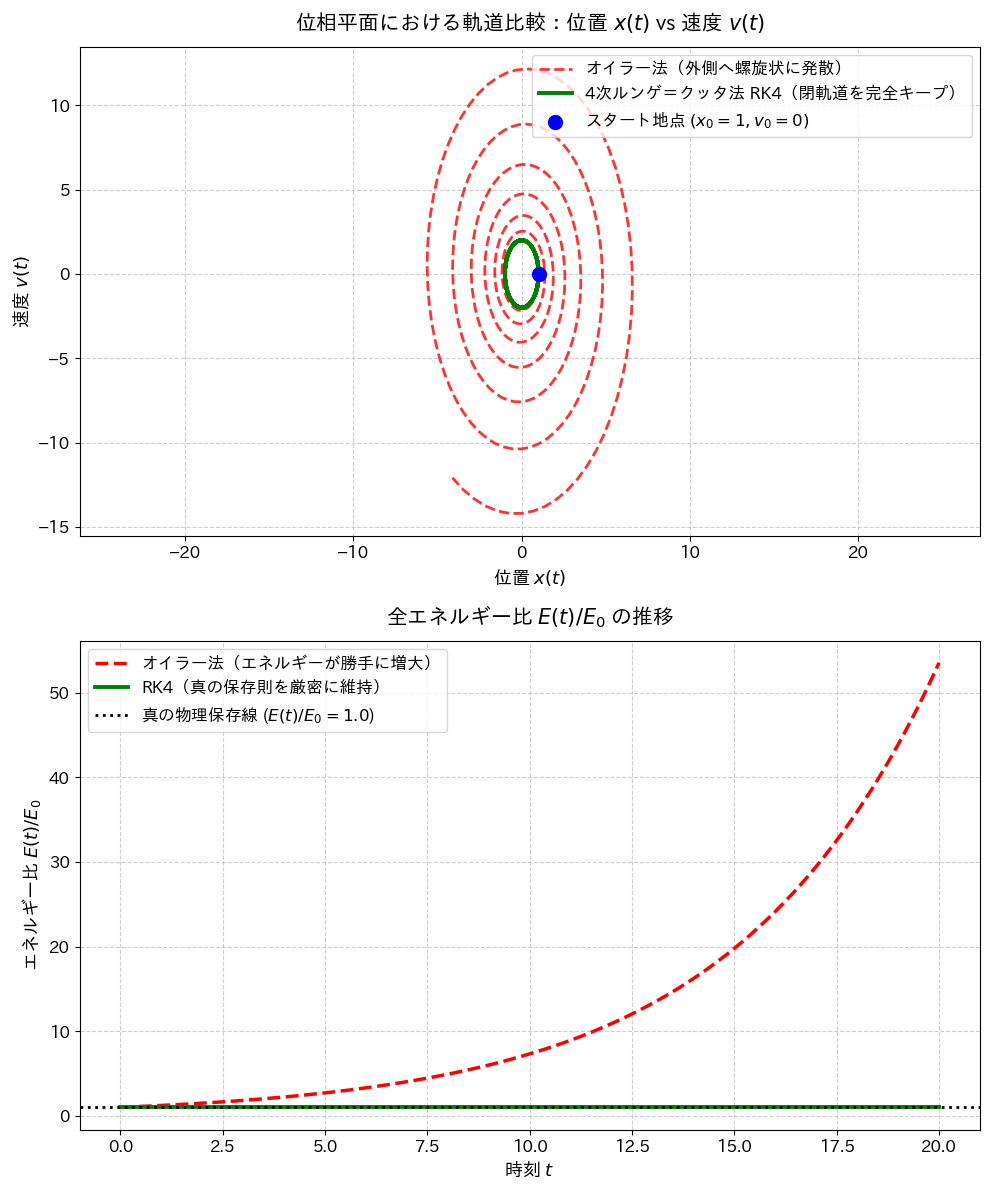

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 単振動の微分方程式: state = [位置 x, 速度 v]
omega = 2.0  # 角振動数

def harmonic_deriv(t, state):
    x, v = state
    return np.array([v, -omega**2 * x])

# 2. ベクトル版オイラー法 & RK4
def euler_step_vec(f, t, y, h):
    return y + h * f(t, y)

def rk4_step_vec(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# 3. シミュレーション実行
t0, t_end = 0.0, 20.0
h = 0.05
n_steps = int(round((t_end - t0) / h))

t_arr = np.linspace(t0, t_end, n_steps + 1)
y0 = np.array([1.0, 0.0])  # 初期条件: 位置 x=1.0, 速度 v=0.0

y_euler = np.zeros((n_steps + 1, 2))
y_rk4 = np.zeros((n_steps + 1, 2))
y_euler[0] = y0
y_rk4[0] = y0

for n in range(n_steps):
    t_curr = t_arr[n]
    y_euler[n + 1] = euler_step_vec(harmonic_deriv, t_curr, y_euler[n], h)
    y_rk4[n + 1] = rk4_step_vec(harmonic_deriv, t_curr, y_rk4[n], h)

# 全エネルギー E(t) = 0.5 * v^2 + 0.5 * omega^2 * x^2
E0 = 0.5 * y0[1]**2 + 0.5 * omega**2 * y0[0]**2
E_euler = 0.5 * y_euler[:, 1]**2 + 0.5 * omega**2 * y_euler[:, 0]**2
E_rk4 = 0.5 * y_rk4[:, 1]**2 + 0.5 * omega**2 * y_rk4[:, 0]**2

print(f"初期エネルギー E0: {E0:.4f}")
print(f"最終時刻でのオイラー法のエネルギー: {E_euler[-1]:.4f} （初期値の {E_euler[-1]/E0:.1f} 倍に増大）")
print(f"最終時刻での RK4 のエネルギー    : {E_rk4[-1]:.6f} （初期値比 {E_rk4[-1]/E0:.6f}、極めて正確に保存）")

# 4. 可視化（縦に並べて大きく描画）
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

# 上図：位相平面の軌道 (x vs v)
ax1.plot(y_euler[:, 0], y_euler[:, 1], 'r--', lw=2.0, alpha=0.8, label='オイラー法（外側へ螺旋状に発散）')
ax1.plot(y_rk4[:, 0], y_rk4[:, 1], 'g-', lw=2.8, label='4次ルンゲ＝クッタ法 RK4（閉軌道を完全キープ）')
ax1.scatter([y0[0]], [y0[1]], color='blue', s=100, zorder=5, label='スタート地点 $(x_0=1, v_0=0)$')
ax1.set_title('位相平面における軌道比較：位置 $x(t)$ vs 速度 $v(t)$', fontsize=15, pad=12)
ax1.set_xlabel('位置 $x(t)$', fontsize=13)
ax1.set_ylabel('速度 $v(t)$', fontsize=13)
ax1.axis('equal')
ax1.tick_params(labelsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=12, loc='upper right')

# 下図：エネルギーの時間変化
ax2.plot(t_arr, E_euler / E0, 'r--', lw=2.5, label='オイラー法（エネルギーが勝手に増大）')
ax2.plot(t_arr, E_rk4 / E0, 'g-', lw=2.8, label='RK4（真の保存則を厳密に維持）')
ax2.axhline(1.0, color='black', linestyle=':', lw=2.0, label='真の物理保存線 ($E(t)/E_0 = 1.0$)')
ax2.set_title('全エネルギー比 $E(t) / E_0$ の推移', fontsize=15, pad=12)
ax2.set_xlabel('時刻 $t$', fontsize=13)
ax2.set_ylabel('エネルギー比 $E(t) / E_0$', fontsize=13)
ax2.tick_params(labelsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=12, loc='upper left')

plt.tight_layout()
plt.show()

---
## 4. 実際の計算での落とし穴 2：急激に変化する現象と「歩幅の限界」

ルンゲ＝クッタ法（RK4）は強力ですが、どんな問題でも万能というわけではありません。  
化学反応や電子回路のように、**「急激に減衰する成分」** を含む現象（専門用語で **「硬い方程式（Stiff ODE）」** と呼びます）では、歩幅 $h$ をある限界（安定限界 $h_{\text{crit}}$）以上に広げると、数値計算上の誤差が増幅され、解が激しく振動して発散します。

RK4 であっても、歩幅 $h$ には限界値が存在します。  
限界を超えた歩幅（$h = 0.060$）を設定すると、解が振動して発散する様子を観察してみましょう。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 急減衰成分を含む微分方程式: lambda = -50
# 真の解は穏やかな波 y(t) = sin(t) ですが、急減衰モードを持ちます
lam = -50.0

def f_stiff(t, y):
    return lam * (y - np.sin(t)) + np.cos(t)

def y_stiff_true(t):
    return np.sin(t)

# 2. RK4 のステップ更新
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# RK4 の理論的安定限界歩幅: h_crit ≒ 2.785 / 50 ≒ 0.0557
h_crit = 2.785 / abs(lam)
print(f"この問題における RK4 の安定限界歩幅: h_crit ≒ {h_crit:.4f}")

# 3. 異なる歩幅 h での比較実験
test_cases = [
    ("安全な歩幅 (h = 0.040)", 0.040, 'g-'),
    ("限界ギリギリ (h = 0.052)", 0.052, 'm--'),
    ("限界超過・発散 (h = 0.060)", 0.060, 'r-')
]

plt.figure(figsize=(10, 6.5))
t_end = 6.0

for label, h_val, style in test_cases:
    t = 0.0
    y = 0.0
    t_list = [t]
    y_list = [y]
    diverged = False
    
    n_steps = int(round(t_end / h_val))
    for step in range(n_steps):
        y = rk4_step(f_stiff, t, y, h_val)
        t += h_val
        if abs(y) > 1e12 or np.isnan(y):
            diverged = True
            print(f"⚠️ {label}: ステップ {step} (t={t:.2f}) で解が発散！")
            break
        t_list.append(t)
        y_list.append(y)
        
    if not diverged:
        print(f"✅ {label}: 終点まで安定！ 最終誤差: {abs(y - y_stiff_true(t)):.2e}")
        
    plt.plot(t_list, y_list, style, lw=2.5, label=label, alpha=0.85)

# スタイリング
t_fine = np.linspace(0, t_end, 300)
plt.plot(t_fine, y_stiff_true(t_fine), 'k:', lw=2.2, label='真の解 $y(t) = \\sin(t)$')
plt.ylim(-2.5, 2.5)  # 振動・発散を見やすくするため縦軸をクリップ
plt.title(f'急変現象におけるRK4の挙動（歩幅の限界 h_crit ≒ {h_crit:.4f}）', fontsize=15, pad=12)
plt.xlabel('時刻 $t$', fontsize=13)
plt.ylabel('$y(t)$', fontsize=13)
plt.tick_params(labelsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left', fontsize=12)

plt.tight_layout()
plt.show()

---
## 5. （参考）歩幅を自動調整するアルゴリズム（適応刻み幅制御）

これまでの実験から分かるように、歩幅 $h$ を固定していると：
- 急激に変化する場所では、歩幅が大きすぎると精度が落ちたり発散したりする。
- 一方で、平坦で緩やかに変化する場所でも小さな歩幅のままだと、計算回数が増えすぎて無駄が生じる。

そこで実務の数値計算ライブラリ（Python の SciPy `solve_ivp` や MATLAB の `ode45` など）では、**「解の急変度合いに応じて歩幅 $h$ を自動的に伸び縮みさせるアルゴリズム（適応刻み幅制御：RK45 / Dormand-Prince法など）」** が標準的に使われています。

急カーブでは歩幅を自動で細かく刻み、見通しの良い直線では歩幅を大きく広げて一気に進むことで、高い精度と高速な計算速度を両立させています。

---
## 6. 実社会での実例展開

ルンゲ＝クッタ法（RK4）は、抽象的な数学の演習にとどまらず、社会を支える最前線のシミュレーション現場で日々稼働しています。  
ここでは、２つの応用事例 を取り上げます：

1. **電気電子工学**: スイッチを入れた瞬間の回路応答（直列RLC過渡現象）
2. **データサイエンス**: ウイルスの感染流行プロセス（SIR感染症モデル）

---
### 6.1 電気電子工学：直列RLC回路の過渡現象シミュレーション

スマホやPCの電源を入れた瞬間、電子回路の中では電圧や電流が急激に変化します。  
直流電源 $E$、スイッチ $S$、抵抗 $R$、コイル $L$、コンデンサ $C$ を直列につないだ回路を考えます。

<div align="center">
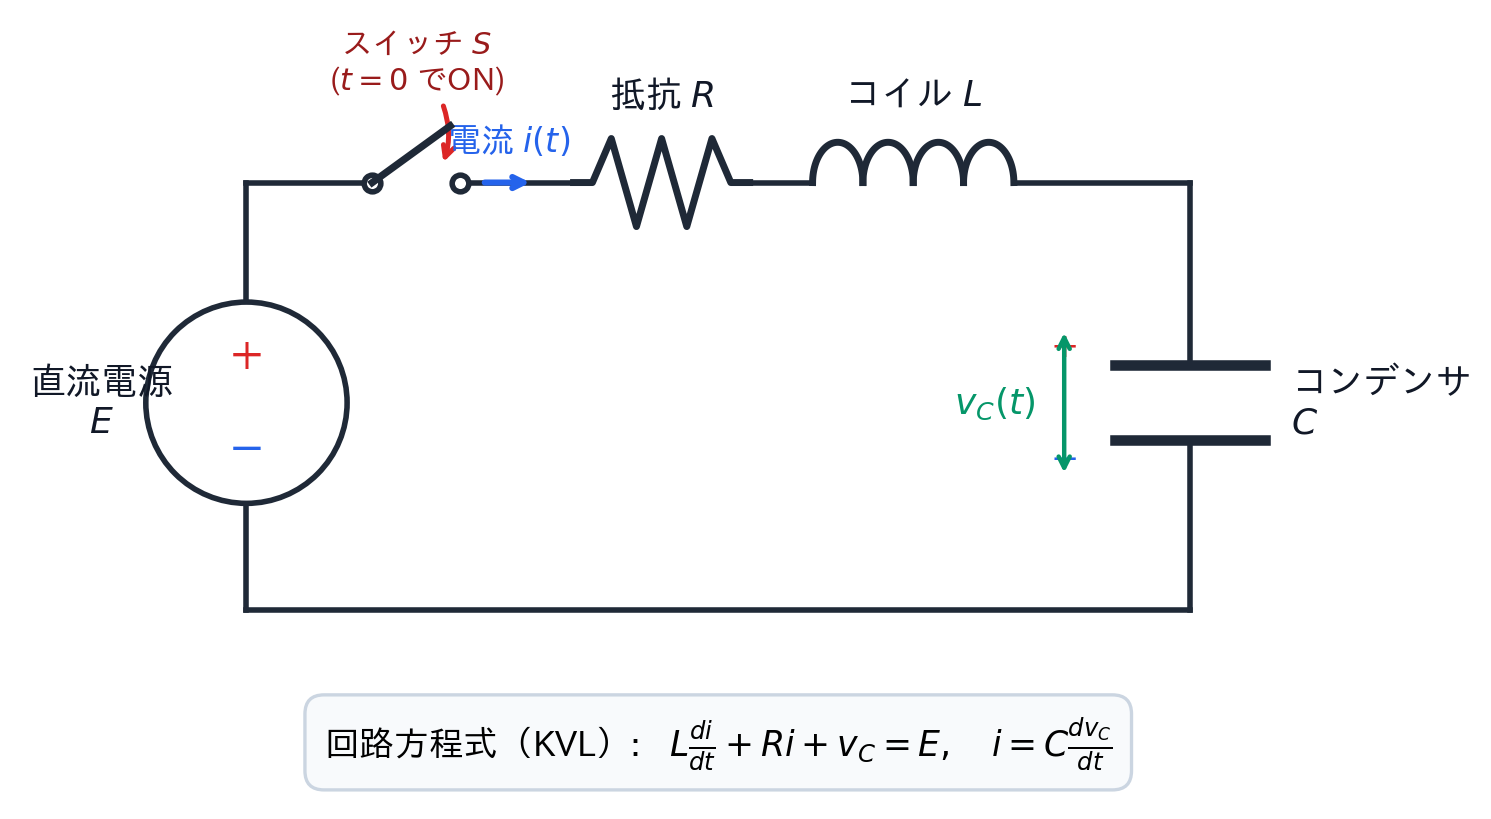
</div>

#### 回路方程式
スイッチを閉じたあとの電圧の釣り合い（キルヒホッフ則）は、電荷 $q(t)$ と電流 $i(t) = \frac{dq}{dt}$ を用いて次のように表されます：

$$
L \frac{di}{dt} + R i + \frac{q}{C} = E
$$

状態変数ベクトルとして $\begin{bmatrix} q \\ i \end{bmatrix}$ を選ぶと、連立1階常微分方程式に変換できます：

$$
\frac{d}{dt} \begin{bmatrix} q \\ i \end{bmatrix} = \begin{bmatrix} i \\ \frac{E - R i - q/C}{L} \end{bmatrix}
$$

コンデンサの両端電圧は $v_C(t) = \frac{q(t)}{C}$ です。

抵抗 $R$ の大きさによって、回路の動きは3つのタイプに分かれます：
1. **不足減衰（抵抗が小さい）**: コンデンサ電圧が $10\,\text{V}$ を飛び越えて激しく揺れる（オーバーシュート）。
2. **臨界減衰（最適な抵抗 $R_{\text{crit}} = 2\sqrt{L/C}$）**: 揺れずに最速で $10\,\text{V}$ にピタッと安定する（エンジニアの理想設計）。
3. **過減衰（抵抗が大きすぎる）**: 電流が流れにくく、$10\,\text{V}$ に達するまでダラダラと時間がかかる。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 回路定数
L = 0.1          # コイル: 100 mH
C = 100e-6       # コンデンサ: 100 uF
E = 10.0         # 電源電圧: 10 V

# 最も理想的な臨界抵抗値 R_crit ≒ 63.2 Ω
R_crit = 2.0 * np.sqrt(L / C)

cases = [
    ("不足減衰 (R = 10 Ω, 振動オーバーシュート)", 10.0, 'r-'),
    (f"臨界減衰 (R = {R_crit:.1f} Ω, 最速ピタッと安定)", R_crit, 'g-'),
    ("過減衰 (R = 250 Ω, ゆっくり立ち上がり)", 250.0, 'b-')
]

# 2. 多変数RK4ステップ
def rk4_step_vec(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# 3. シミュレーション実行
t0, t_end, dt = 0.0, 0.08, 0.0001
n_steps = int(round((t_end - t0) / dt))
t_arr = np.linspace(t0, t_end, n_steps + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 11))

for label, R, style in cases:
    # state = [電荷 q, 電流 i]
    def rlc_ode(t, state):
        q, i = state
        return np.array([i, (E - R * i - q / C) / L])
    
    y = np.zeros(2)
    vC_hist = [y[0] / C]
    i_hist = [y[1]]
    
    for step in range(n_steps):
        y = rk4_step_vec(rlc_ode, t_arr[step], y, dt)
        vC_hist.append(y[0] / C)
        i_hist.append(y[1])
        
    print(f"{label:<32}: 最大電圧 = {max(vC_hist):.2f} V, 最終電圧 = {vC_hist[-1]:.2f} V")
    ax1.plot(t_arr * 1000, vC_hist, style, lw=2.5, label=label)
    ax2.plot(t_arr * 1000, i_hist, style, lw=2.5, label=label)

# 上図：コンデンサ電圧
ax1.axhline(E, color='black', linestyle=':', lw=2.0, label='電源電圧 E = 10 V')
ax1.set_title('直列RLC回路のコンデンサ電圧 $v_C(t)$ のステップ応答', fontsize=15, pad=12)
ax1.set_xlabel('時間 [ms]', fontsize=13)
ax1.set_ylabel('コンデンサ電圧 $v_C$ [V]', fontsize=13)
ax1.tick_params(labelsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='lower right', fontsize=11)

# 下図：回路電流
ax2.set_title('回路を流れる過渡電流 $i(t)$ の変化', fontsize=15, pad=12)
ax2.set_xlabel('時間 [ms]', fontsize=13)
ax2.set_ylabel('電流 $i$ [A]', fontsize=13)
ax2.tick_params(labelsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

---
### 6.2 データサイエンス：感染症数理SIRモデルのシミュレーション

感染症の数理モデリングにおいて、基礎的かつ古典的な理論モデルとして広く知られているのが **SIRモデル**（Kermack-McKendrickモデル）です。  
個体群全体の感染拡大プロセスを、未感染者・感染者・回復者の人数の時間変化として記述する連立常微分方程式です。

全人口 $N$ を3つのグループに分類します：
- **$S(t)$（Susceptible: 感受性者）**: 未感染で抗体を持たない人
- **$I(t)$（Infectious: 感染者）**: 現在ウイルスに感染しており、他人にうつす人
- **$R(t)$（Recovered: 回復者）**: 回復して免疫を獲得した人

相互作用を表す微分方程式：
$$
\frac{dS}{dt} = -\beta \frac{S I}{N}, \quad \frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \quad \frac{dR}{dt} = \gamma I
$$

途中で外出自粛やマスク着用などの行動変容（介入）を行って感染率 $\beta$ を下げた場合に、感染ピークがどのように抑制されるか（**曲線の平坦化: Flatten the Curve**）を RK4 でシミュレーションします。

【対策なし】: ピーク時感染者数 3566 人 (Day 31.8)
【対策あり】: ピーク時感染者数 1434 人 (Day 33.5)
-> 適切な対策によりピーク感染者数を 約 59.8% 削減！


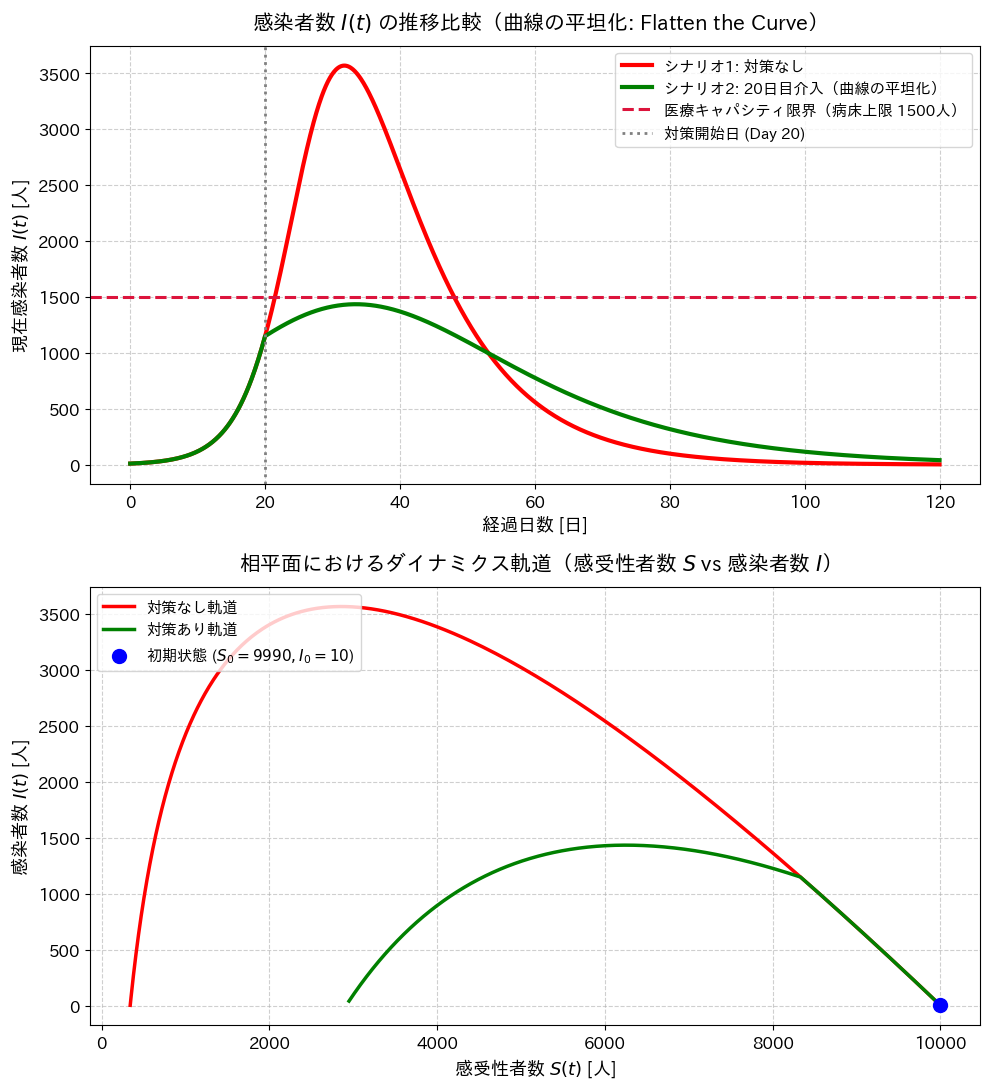

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 1. 人口パラメータと感染定数
N = 10000.0       # 総人口: 1万人
gamma = 0.1       # 回復率 (平均10日で治る)

# 2. 多変数RK4
def rk4_step_vec(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# 3. シミュレーション関数
def simulate_sir(beta_func, t_end=120.0, dt=0.1):
    n_steps = int(round(t_end / dt))
    t_arr = np.linspace(0, t_end, n_steps + 1)
    y = np.array([9990.0, 10.0, 0.0])  # 最初は感染者10人
    history = [y.copy()]
    
    for step in range(n_steps):
        t_curr = t_arr[step]
        beta_curr = beta_func(t_curr)
        
        def sir_ode(t, state):
            S, I, R = state
            dS = -beta_curr * S * I / N
            dI = beta_curr * S * I / N - gamma * I
            dR = gamma * I
            return np.array([dS, dI, dR])
            
        y = rk4_step_vec(sir_ode, t_curr, y, dt)
        history.append(y.copy())
        
    return t_arr, np.array(history)

# シナリオ1：対策なし（R0 = 3.5）
t_arr1, hist1 = simulate_sir(lambda t: 0.35)

# シナリオ2：20日目に行動変容対策を実施（R0: 3.5 -> 1.6）
def beta_intervention(t):
    return 0.35 if t < 20.0 else 0.16

t_arr2, hist2 = simulate_sir(beta_intervention)

peak1_idx = np.argmax(hist1[:, 1])
peak2_idx = np.argmax(hist2[:, 1])

print(f"【対策なし】: ピーク時感染者数 {hist1[peak1_idx, 1]:.0f} 人 (Day {t_arr1[peak1_idx]:.1f})")
print(f"【対策あり】: ピーク時感染者数 {hist2[peak2_idx, 1]:.0f} 人 (Day {t_arr2[peak2_idx]:.1f})")
print(f"-> 適切な対策によりピーク感染者数を 約 {(1.0 - hist2[peak2_idx, 1]/hist1[peak1_idx, 1])*100:.1f}% 削減！")

# 4. 可視化（縦に並べて大きく描画）
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 11))

# 上図：感染者数 I(t) の推移（Flatten the Curve）
ax1.plot(t_arr1, hist1[:, 1], 'r-', lw=3.0, label='シナリオ1: 対策なし')
ax1.plot(t_arr2, hist2[:, 1], 'g-', lw=3.0, label='シナリオ2: 20日目介入（曲線の平坦化）')
ax1.axhline(1500, color='crimson', linestyle='--', lw=2.2, label='医療キャパシティ限界（病床上限 1500人）')
ax1.axvline(20, color='gray', linestyle=':', lw=2.0, label='対策開始日 (Day 20)')
ax1.set_title('感染者数 $I(t)$ の推移比較（曲線の平坦化: Flatten the Curve）', fontsize=15, pad=12)
ax1.set_xlabel('経過日数 [日]', fontsize=13)
ax1.set_ylabel('現在感染者数 $I(t)$ [人]', fontsize=13)
ax1.tick_params(labelsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', fontsize=11)

# 下図：相平面ダイナミクス (S vs I)
ax2.plot(hist1[:, 0], hist1[:, 1], 'r-', lw=2.5, label='対策なし軌道')
ax2.plot(hist2[:, 0], hist2[:, 1], 'g-', lw=2.5, label='対策あり軌道')
ax2.scatter([hist1[0, 0]], [hist1[0, 1]], color='blue', s=100, zorder=5, label='初期状態 ($S_0=9990, I_0=10$)')
ax2.set_title('相平面におけるダイナミクス軌道（感受性者数 $S$ vs 感染者数 $I$）', fontsize=15, pad=12)
ax2.set_xlabel('感受性者数 $S(t)$ [人]', fontsize=13)
ax2.set_ylabel('感染者数 $I(t)$ [人]', fontsize=13)
ax2.tick_params(labelsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()